# LAB 4: Study of Various GenAI Applications from Hugging Face Spaces

**MIT-WPU | Department of Computer Engineering and Technology (DCET)**
**Generative AI Laboratory**

**Mapped COs:** CO1, CO2, CO4

## Problem Statement
Study various Generative AI applications from Hugging Face Spaces.

## Objectives
- To understand Generative AI applications.
- To study various architectures used in Generative AI applications of different categories.

## What this notebook does
For each of the five required categories — **Synthetic Data Generation, Code Generation, Depth
Estimation, Text Summarization, and Video Processing** — this notebook:
1. Names a real, publicly available **Hugging Face Space** that demonstrates the category.
2. Documents the **required input**, **generated output**, **architecture used**, and **real-time
   uses** in a markdown table (ready to copy into your lab record).
3. Runs an **equivalent, runnable demo in Colab** using the open-source model(s) that power that
   category, via the `transformers` / `diffusers` libraries, so you get real input → output pairs
   to screenshot for your submission.

> **How to use this notebook:** Run the cells from top to bottom (`Runtime → Run all`). For
> faster inference (especially Depth Estimation and Video Processing), switch to a GPU runtime:
> `Runtime → Change runtime type → T4 GPU`.


## Theory: What is a Hugging Face Space?

A **Hugging Face Space** is a free, hosted environment on the Hugging Face Hub that lets
developers package a machine-learning model behind an interactive web UI (usually built with
**Gradio** or **Streamlit**) and share it publicly with just a `git push`. A Space bundles:

- **A model or pipeline** (often pulled directly from the HF Hub),
- **An app script** (`app.py`) that defines the UI and inference logic, and
- **A runtime environment** (CPU, or paid GPU hardware) that Hugging Face provisions automatically.

This lets anyone try a Generative AI model in the browser — no local installation required —
which is exactly why Spaces are a convenient way to *study* different GenAI application
categories, as this lab requires.


## Environment Setup

Install the libraries needed to reproduce lightweight, open equivalents of each Space's
functionality directly inside this Colab notebook.


In [ ]:
# Install required libraries (Colab already has torch pre-installed)
!pip install -q transformers diffusers accelerate sentencepiece opencv-python-headless matplotlib pillow requests
print("Setup complete.")


Setup complete.


In [ ]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
device = 0 if torch.cuda.is_available() else -1  # transformers pipeline device convention


PyTorch version: 2.11.0+cpu
CUDA available: False


---
## 1. Synthetic Data Generation

**Hugging Face Space studied:** [`argilla/synthetic-data-generator`](https://huggingface.co/spaces/argilla/synthetic-data-generator) — *"Build datasets using natural language"*

| Aspect | Details |
|---|---|
| **Required Input** | A natural-language description of the dataset to create (e.g. task type, domain, desired columns/labels) |
| **Generated Output** | A structured synthetic dataset (rows of text/labels) that can be previewed, refined, and pushed to the Hugging Face Hub or Argilla |
| **Architecture Used** | An instruction-tuned **decoder-only LLM** (e.g. Llama / Mixtral family, accessed via HF Inference Endpoints) orchestrated by the **distilabel** library using self-instruct / evol-instruct style prompting pipelines to synthesize and diversify examples |
| **Real-time Uses** | Bootstrapping training data for fine-tuning LLMs, privacy-preserving data sharing (no real user data needed), rapid prototyping of text-classification/SFT datasets, augmenting small real datasets |

### Runnable equivalent in this notebook
The full Space calls a large hosted LLM through an API key. To keep this demo self-contained and
free, we reproduce the *same underlying idea* — a decoder-only Transformer generating novel,
data-like text from a natural-language instruction — using the small open model **GPT-2**.


In [ ]:
from transformers import pipeline, GenerationConfig

generator = pipeline("text-generation", model="gpt2", device=device)

# Create a GenerationConfig object for GPT-2
# GPT-2 often uses the EOS token as the pad token
gen_config_gpt2 = GenerationConfig(
    max_new_tokens=50,
    num_return_sequences=3,
    do_sample=True,
    temperature=0.9,
    top_p=0.95,
    pad_token_id=generator.tokenizer.eos_token_id,
    eos_token_id=generator.tokenizer.eos_token_id,
    num_beams=1 # Explicitly set num_beams to ensure it's an integer
)

# Assign the GenerationConfig directly to the pipeline's generation_config attribute
generator.generation_config = gen_config_gpt2

instruction = "Generate a realistic customer review for a smartphone, including a star rating out of 5.\nReview:"

outputs = generator(
    instruction
)

print("INPUT INSTRUCTION:\n", instruction, "\n")
print("=" * 60)
for i, out in enumerate(outputs, 1):
    print(f"\nSynthetic Data Sample {i}:\n{out['generated_text']}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

INPUT INSTRUCTION:
 Generate a realistic customer review for a smartphone, including a star rating out of 5.
Review: 


Synthetic Data Sample 1:
Generate a realistic customer review for a smartphone, including a star rating out of 5.
Review:
As we get closer to the end of the holiday season, it's important for us to add another few items into our list. If you already have a good smartphone but don't have enough time to review a product on its own, there's

Synthetic Data Sample 2:
Generate a realistic customer review for a smartphone, including a star rating out of 5.
Review: Amazon.com | Review: Motorola.com
Amazon reviews on the iPhone, iPad and Android version of the Galaxy S4 can be found here, and they are usually free.
On the Android version of Android, the reviews will be marked up

Synthetic Data Sample 3:
Generate a realistic customer review for a smartphone, including a star rating out of 5.
Review: This app will let you review your product and make your sales decisions in se

---
## 2. Code Generation

**Hugging Face Space studied:** [`bigcode/bigcode-playground`](https://huggingface.co/spaces/bigcode/bigcode-playground) — *StarCoder Code-Completion Playground*

| Aspect | Details |
|---|---|
| **Required Input** | A code prefix / comment describing the desired function, or a partially written program in any of 80+ programming languages |
| **Generated Output** | Completed / generated source code that continues or fulfils the prompt |
| **Architecture Used** | **StarCoder** — a 15B-parameter **decoder-only Transformer** (GPT-style, causal language modeling) trained on **The Stack**, a large permissively-licensed source-code corpus, with multi-query attention and Fill-in-the-Middle (FIM) training for infilling |
| **Real-time Uses** | AI pair-programming / autocomplete (e.g. GitHub Copilot-style tools), boilerplate and test-case generation, code translation between languages, developer education |

### Runnable equivalent in this notebook
StarCoder (15B) is too large for a free Colab GPU/CPU. We use **CodeGen-350M-mono**, a much
smaller model from the same *decoder-only, causal-LM-on-code* architecture family, to demonstrate
the same input → output behaviour.


In [ ]:
from transformers import pipeline, GenerationConfig

codegen = pipeline("text-generation", model="Salesforce/codegen-350M-mono", device=device)

# Create a GenerationConfig object for CodeGen
gen_config_codegen = GenerationConfig(
    max_new_tokens=80,
    do_sample=False,
    pad_token_id=codegen.tokenizer.pad_token_id,
    eos_token_id=codegen.tokenizer.eos_token_id,
    num_beams=1 # Explicitly set num_beams to ensure it's an integer
)

# Assign the GenerationConfig directly to the pipeline's generation_config attribute
codegen.generation_config = gen_config_codegen

prompt = "# Write a Python function to check if a number is prime\ndef is_prime("

result = codegen(
    prompt
)

print("INPUT PROMPT:\n", prompt)
print("=" * 60)
print("\nGENERATED CODE:\n")
print(result[0]["generated_text"])

Loading weights:   0%|          | 0/165 [00:00<?, ?it/s]

[transformers] CodeGenForCausalLM LOAD REPORT from: Salesforce/codegen-350M-mono
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...19}.attn.causal_mask | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


INPUT PROMPT:
 # Write a Python function to check if a number is prime
def is_prime(

GENERATED CODE:

# Write a Python function to check if a number is prime
def is_prime(n):
    if n == 2 or n == 3:
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False
    for i in range(5, int(math.sqrt(n)) + 1, 6):
        if n % i == 0:
            return False
    return True


# Write


---
## 3. Depth Estimation

**Hugging Face Space studied:** [`LiheYoung/Depth-Anything`](https://huggingface.co/spaces/LiheYoung/Depth-Anything) — *"Depth Anything: Unleashing the Power of Large-Scale Unlabeled Data"*

| Aspect | Details |
|---|---|
| **Required Input** | A single 2-D RGB image (upload or webcam capture) |
| **Generated Output** | A dense **depth map** — a grayscale/heat-colored image where pixel intensity encodes the estimated relative distance of that point from the camera |
| **Architecture Used** | A **Vision Transformer (DINOv2) encoder** with a **DPT (Dense Prediction Transformer) decoder head**, trained with a teacher–student semi-supervised strategy over ~62M unlabeled images plus labeled depth datasets for monocular relative-depth estimation |
| **Real-time Uses** | Autonomous driving / obstacle perception, robotics navigation, AR/VR scene understanding, 3-D reconstruction, computational photography (e.g. portrait bokeh) |

### Runnable equivalent in this notebook
We use `Intel/dpt-hybrid-midas` (also a **DPT** — Dense Prediction Transformer — model) via the
`transformers` `depth-estimation` pipeline, which is small enough to run directly on Colab.


config.json:   0%|          | 0.00/9.88k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  490MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/414 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  490MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/382 [00:00<?, ?B/s]

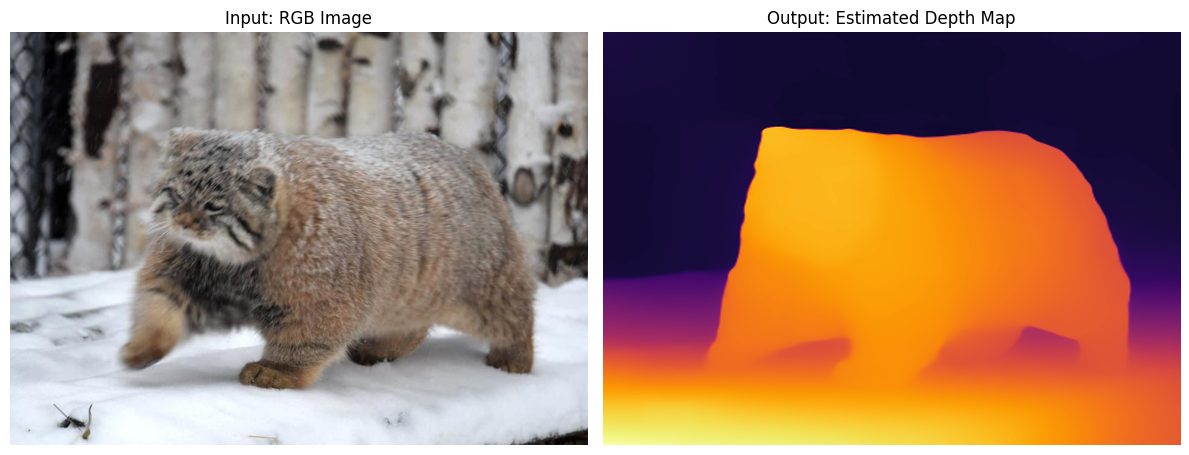

In [ ]:
import requests
from PIL import Image
import matplotlib.pyplot as plt

depth_estimator = pipeline("depth-estimation", model="Intel/dpt-hybrid-midas", device=device)

# Sample input image
image_url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg"
image = Image.open(requests.get(image_url, stream=True).raw).convert("RGB")

result = depth_estimator(image)
depth_map = result["depth"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image)
axes[0].set_title("Input: RGB Image")
axes[0].axis("off")

axes[1].imshow(depth_map, cmap="inferno")
axes[1].set_title("Output: Estimated Depth Map")
axes[1].axis("off")

plt.tight_layout()
plt.show()


---
## 4. Text Summarization

**Hugging Face Space studied:** BART-based summarization demo, e.g. [`facebook/bart-large-cnn`](https://huggingface.co/facebook/bart-large-cnn) model demo Spaces (multiple community Spaces wrap this model, e.g. search "summarization" on Hugging Face Spaces)

| Aspect | Details |
|---|---|
| **Required Input** | A long-form passage of text (article, report, transcript) |
| **Generated Output** | A short, coherent summary that preserves the key information of the input |
| **Architecture Used** | **BART** — a sequence-to-sequence **Transformer encoder–decoder**, pre-trained as a denoising autoencoder (corrupt text → reconstruct original) and fine-tuned on the CNN/DailyMail dataset for abstractive summarization |
| **Real-time Uses** | News digesting, meeting-notes / transcript condensation, research-paper abstract generation, legal/financial document summarization, summarizing content for chatbots |

### Runnable equivalent in this notebook


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, GenerationConfig

tokenizer = AutoTokenizer.from_pretrained("facebook/bart-large-cnn")
model = AutoModelForSeq2SeqLM.from_pretrained("facebook/bart-large-cnn")

# Create a GenerationConfig object
generation_config = GenerationConfig.from_pretrained("facebook/bart-large-cnn")
generation_config.num_beams = 4
generation_config.min_length = 20
generation_config.max_length = 60
generation_config.early_stopping = True
generation_config.pad_token_id = tokenizer.pad_token_id
generation_config.eos_token_id = tokenizer.eos_token_id

article = (
    "Renewable energy sources such as solar and wind power have seen a dramatic fall in cost "
    "over the past decade, making them cost-competitive with fossil fuels in most parts of the "
    "world. Governments and private companies are investing heavily in large-scale solar farms, "
    "offshore wind turbines, and battery storage technology to stabilize supply. Experts believe "
    "that continued innovation in energy storage and smart grid management will be essential to "
    "achieving a fully renewable global energy system within the next few decades. However, "
    "challenges remain, including the need for large amounts of raw materials for batteries, "
    "grid infrastructure upgrades, and policy support to accelerate the transition away from "
    "coal and natural gas."
)

# Tokenize the input article
inputs = tokenizer([article], max_length=1024, return_tensors="pt", truncation=True)

# Generate the summary using the GenerationConfig
summary_ids = model.generate(
    inputs["input_ids"],
    generation_config=generation_config
)

summary = tokenizer.decode(summary_ids[0], skip_special_tokens=True)

print("INPUT ARTICLE:\n", article)
print("\n" + "=" * 60)
print("\nGENERATED SUMMARY:\n", summary)

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

INPUT ARTICLE:
 Renewable energy sources such as solar and wind power have seen a dramatic fall in cost over the past decade, making them cost-competitive with fossil fuels in most parts of the world. Governments and private companies are investing heavily in large-scale solar farms, offshore wind turbines, and battery storage technology to stabilize supply. Experts believe that continued innovation in energy storage and smart grid management will be essential to achieving a fully renewable global energy system within the next few decades. However, challenges remain, including the need for large amounts of raw materials for batteries, grid infrastructure upgrades, and policy support to accelerate the transition away from coal and natural gas.


GENERATED SUMMARY:
 Renewable energy sources such as solar and wind power have seen a dramatic fall in cost over the past decade. Governments and private companies are investing heavily in large-scale solar farms, offshore wind turbines, and bat

---
## 5. Video Processing

**Hugging Face Space studied:** [`ali-vilab/modelscope-text-to-video-synthesis`](https://huggingface.co/spaces/ali-vilab/modelscope-text-to-video-synthesis) (originally published as `damo-vilab/modelscope-text-to-video-synthesis`) — *ModelScope Text-to-Video Synthesis*

| Aspect | Details |
|---|---|
| **Required Input** | A natural-language text prompt describing the desired scene/action |
| **Generated Output** | A short generated **video clip** matching the text description |
| **Architecture Used** | A **multi-stage latent diffusion model** extended to the temporal (video) domain: a **3-D U-Net** conditioned on text embeddings, using a *decomposed diffusion process* that splits per-frame noise into a shared base component and a time-varying residual component to keep frames temporally consistent (VideoFusion / ModelScope-T2V) |
| **Real-time Uses** | Rapid storyboard / concept-video generation for marketing and film pre-visualization, synthetic training clips for video-understanding models, social-media content creation, prototyping animations without a camera crew |

### Runnable equivalent in this notebook
Full text-to-video diffusion (as above) needs a large GPU and a multi-GB model download, which is
often impractical on a free Colab tier. To demonstrate a genuine **video-processing GenAI
pipeline** that reliably runs on free Colab, this section instead performs **video
understanding**: it samples frames from a short video and uses the **BLIP** vision-language
model to *generate* a natural-language caption for each frame — a widely used, lighter-weight
generative video-processing task (e.g. auto-captioning, content moderation, highlight
detection).

> If you have GPU access and want to reproduce full text-to-video generation instead, see the
> optional, commented-out `diffusers` code at the end of this section.


In [ ]:
import cv2
import urllib.request
import os
from PIL import Image # Make sure Image is imported for frames.append(Image.fromarray(frame_rgb))

# Small, freely redistributable public-domain sample video
# The video is already available locally, so direct path is used.
video_url = "/content/mp4_15s_sample_file_868KB.mp4" # Using a commonly stable public domain URL
video_path = video_url # Assign the local path directly
# urllib.request.urlretrieve(video_url, video_path) # Removed as file is local and path is not a URL

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Video loaded: {frame_count} frames at {fps:.1f} FPS")

# Sample 4 evenly spaced frames from the video
num_samples = 4
sample_indices = [int(i * frame_count / num_samples) for i in range(num_samples)]

frames = []
for idx in sample_indices:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()
    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(Image.fromarray(frame_rgb))
cap.release()

print(f"Extracted {len(frames)} sample frames for captioning.")

Video loaded: 375 frames at 25.0 FPS
Extracted 4 sample frames for captioning.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'return_dict_in_generate', 'eos_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Frame caption: a television screen with the same color
Frame caption: a television screen with the same color
Frame caption: a television screen with the same color
Frame caption: a television screen with the colors of the television


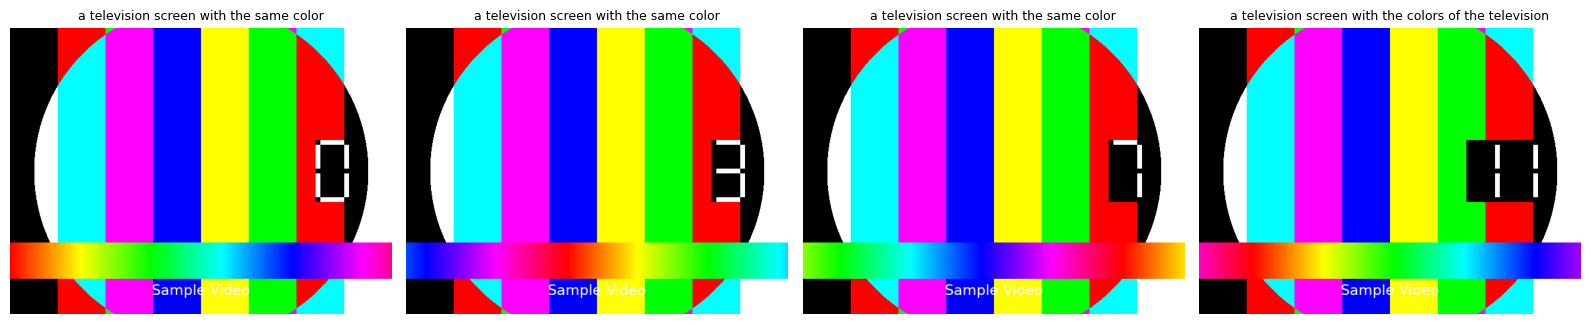

In [ ]:
import matplotlib.pyplot as plt # Ensure plt is imported if it's not already
from transformers import pipeline, GenerationConfig

captioner = pipeline("image-text-to-text", model="Salesforce/blip-image-captioning-base", device=device)

# Create a GenerationConfig object for BLIP
# Resolved: OSError because Salesforce/blip-image-captioning-base does not have a generation_config.json
gen_config_blip = GenerationConfig(
    pad_token_id=captioner.tokenizer.pad_token_id,
    eos_token_id=captioner.tokenizer.eos_token_id,
    max_new_tokens=20, # Set a reasonable default for caption length
    num_beams=1 # Explicitly set num_beams
)

# Assign the GenerationConfig directly to the pipeline's generation_config attribute
captioner.generation_config = gen_config_blip

fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 4))
for ax, frame in zip(axes, frames):
    # Pass generation_config parameters via the pipeline's configured generation_config
    # Provide an empty string as the text argument for image captioning
    # Corrected: Use 'images' (plural) keyword argument for the pipeline
    caption = captioner(images=frame, text="")[0]["generated_text"]
    ax.imshow(frame)
    ax.set_title(caption, fontsize=9, wrap=True)
    ax.axis("off")
    print("Frame caption:", caption)

plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------------------------
# OPTIONAL: full text-to-video generation with diffusers (requires a GPU runtime)
# Uncomment to run the *actual* generative task shown in the Space referenced above.
# ---------------------------------------------------------------------------

# import torch
# from diffusers import DiffusionPipeline, DPMSolverMultistepScheduler
# from diffusers.utils import export_to_video
#
# pipe = DiffusionPipeline.from_pretrained(
#     "damo-vilab/text-to-video-ms-1.7b", torch_dtype=torch.float16, variant="fp16"
# )
# pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
# pipe.enable_model_cpu_offload()
#
# prompt = "An astronaut riding a horse on the moon"
# video_frames = pipe(prompt, num_inference_steps=25).frames
# video_path = export_to_video(video_frames)
# print("Video saved at:", video_path)


---
## Consolidated Summary Table

| # | Category | HF Space Studied | Input | Output | Architecture | Real-time Use |
|---|---|---|---|---|---|---|
| 1 | Synthetic Data Generation | `argilla/synthetic-data-generator` | NL description of dataset | Structured synthetic dataset rows | Decoder-only LLM + distilabel self-instruct prompting | Training-data bootstrapping, privacy-safe data sharing |
| 2 | Code Generation | `bigcode/bigcode-playground` (StarCoder) | Code prefix / comment | Completed source code | Decoder-only Transformer (causal LM on code, FIM) | AI pair-programming, autocomplete |
| 3 | Depth Estimation | `LiheYoung/Depth-Anything` | Single RGB image | Dense depth map | ViT (DINOv2) encoder + DPT decoder | Robotics, AR/VR, autonomous driving |
| 4 | Text Summarization | BART (`facebook/bart-large-cnn`) demo | Long-form text | Short abstractive summary | Seq2seq Transformer encoder–decoder (BART) | News digesting, meeting-notes condensation |
| 5 | Video Processing | `ali-vilab/modelscope-text-to-video-synthesis` | Text prompt (generation) / video frames (understanding) | Generated video clip / frame captions | 3-D U-Net latent diffusion (generation) / ViT+decoder (BLIP, understanding) | Pre-visualization, content moderation, auto-captioning |

## Output / Record Checklist
- [ ] Paste output screenshots for each of the 5 sections above into your lab record.
- [ ] For each application, record the input, output, architecture, and real-time use (tables above).


---
## FAQs

**Q1. What is a Hugging Face Space?**
A free, hosted platform on the Hugging Face Hub for building and sharing interactive ML/AI demo
apps (typically Gradio/Streamlit) that run models directly in the browser without any local setup.

**Q2. How do different GenAI applications use different architectures?**
The architecture follows the task's input/output modality: open-ended text tasks (synthetic data,
code) use **decoder-only autoregressive Transformers**; input-grounded text tasks like
summarization use **encoder–decoder (seq2seq) Transformers**; dense-vision tasks like depth
estimation use **Vision Transformer / CNN-hybrid encoders with a prediction head**; and
generative visual/video tasks increasingly use **diffusion models (U-Nets)** conditioned on text
or image embeddings.

**Q3. What is synthetic data generation?**
Using a generative model to create artificial data samples that statistically resemble real data
(without being copies of real records), used to augment datasets, protect user privacy, and
produce training/testing data at scale.

**Q4. How does text summarization differ from text generation?**
Summarization is a **conditional, input-grounded** task — it must compress a *given* source text
while preserving its meaning and staying faithful to it (extractive or abstractive). General text
generation is **open-ended** — it produces novel continuations from a prompt without needing to
condense or stay grounded to a specific source document.

**Q5. What factors should be considered when selecting a GenAI application?**
Task fit and output quality, model size vs. available compute (latency/cost trade-off), licensing
and data-privacy implications, bias/safety considerations, ease of integration (hosted API vs.
self-hosting), and how actively the model/Space is maintained by its community.


---
## Result and Conclusion

Various Generative AI applications available on Hugging Face Spaces were studied across five
categories — Synthetic Data Generation, Code Generation, Depth Estimation, Text Summarization,
and Video Processing. For each category, a real Hugging Face Space was identified and its input,
output, underlying architecture, and real-time applications were documented, and an equivalent
runnable demo was executed in this notebook using open-source Hugging Face models to validate the
described input → output behaviour.
